In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)



In [2]:
# Generate dataset
X, y_true = make_blobs(
    n_samples=500,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

print("Dataset Shape:", X.shape)

Dataset Shape: (500, 2)


In [3]:
# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# Evaluate different K values
results = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    db_score = davies_bouldin_score(X_scaled, labels)
    ch_score = calinski_harabasz_score(X_scaled, labels)

    results.append({
        "K": k,
        "Silhouette Score": silhouette,
        "Davies-Bouldin": db_score,
        "Calinski-Harabasz": ch_score
    })

In [5]:
# Create results DataFrame
results_df = pd.DataFrame(results)

print("\nClustering Evaluation Results:")
print(results_df.round(3))


Clustering Evaluation Results:
   K  Silhouette Score  Davies-Bouldin  Calinski-Harabasz
0  2             0.549           0.595            447.178
1  3             0.726           0.388           1732.715
2  4             0.756           0.340           3882.314
3  5             0.644           0.630           3281.754
4  6             0.517           0.877           2943.128
5  7             0.427           1.003           2778.644
6  8             0.347           1.116           2698.933


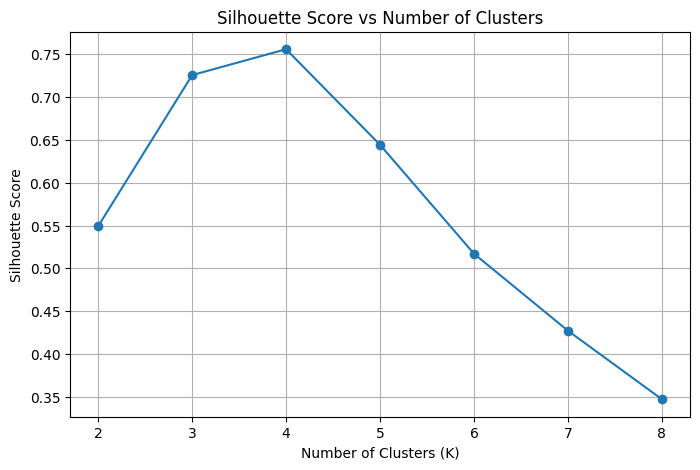

In [6]:
# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["K"],
    results_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(results_df["K"])
plt.grid(True)
plt.show()

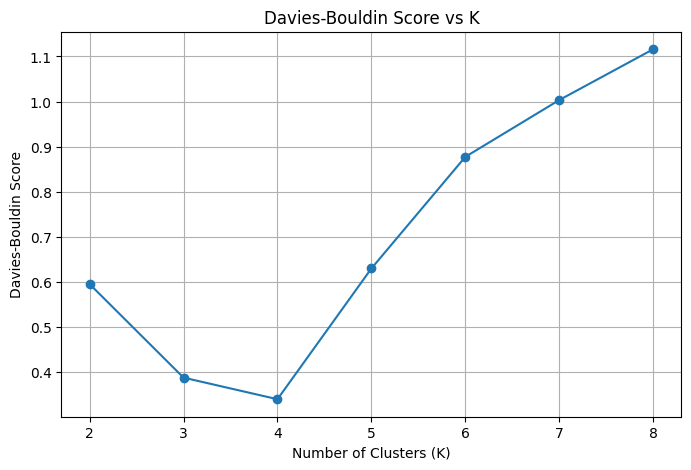

In [7]:
# Plot Davies-Bouldin Scores
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["K"],
    results_df["Davies-Bouldin"],
    marker="o"
)

plt.title("Davies-Bouldin Score vs K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Score")
plt.xticks(results_df["K"])
plt.grid(True)
plt.show()

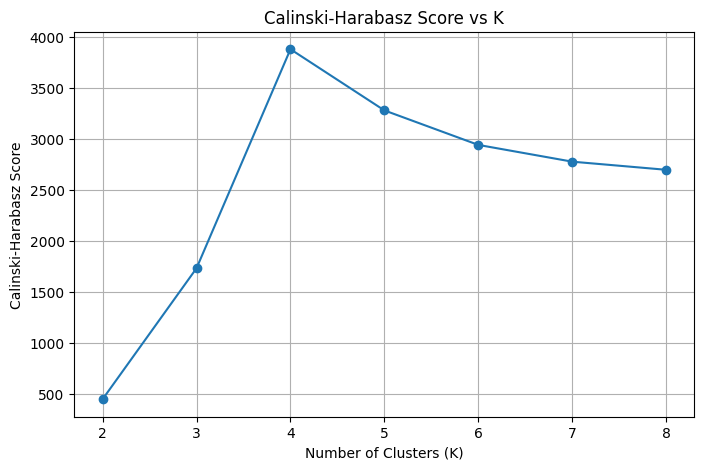

In [8]:
# Plot Calinski-Harabasz Scores
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["K"],
    results_df["Calinski-Harabasz"],
    marker="o"
)

plt.title("Calinski-Harabasz Score vs K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Calinski-Harabasz Score")
plt.xticks(results_df["K"])
plt.grid(True)
plt.show()